# 01 · Exploring the flight sample

Our 3% sample of the Expedia dataset: about 2.46 million rows, 180,000 flights.

Run each cell with **Shift + Enter**.

In [2]:
import pandas as pd

# show all columns instead of hiding some with '...'
pd.set_option('display.max_columns', None)

df = pd.read_parquet('../data/processed/flights_sample_3pct.parquet')

## How big is it? (rows, columns)

In [2]:
df.shape

(2461647, 27)

## The first 5 rows

In [ ]:
df.head()

## Missing values per column

In [ ]:
df.isna().sum()

## Price summary (min, max, average...)

In [5]:
df['totalFare'].describe()

count    2.461647e+06
mean     3.401505e+02
std      1.967838e+02
min      1.959000e+01
25%      1.966000e+02
50%      3.036100e+02
75%      4.521950e+02
max      4.762600e+03
Name: totalFare, dtype: float64

## One flight's price over time

Pick the flight with the most price checks and look at how its price changed.

In [6]:
busiest = df['legId'].value_counts().index[0]
one_flight = df[df['legId'] == busiest].sort_values('searchDate')
one_flight[['searchDate', 'flightDate', 'startingAirport', 'destinationAirport', 'totalFare']]

,searchDate,flightDate,startingAirport,destinationAirport,totalFare
437220,2022-05-21,2022-07-18,DFW,ATL,128.59
478453,2022-05-25,2022-07-18,DFW,ATL,168.59
493814,2022-05-26,2022-07-18,DFW,ATL,168.59
508507,2022-05-27,2022-07-16,DTW,DFW,98.59
523839,2022-05-28,2022-07-16,DTW,DFW,98.59
524277,2022-05-28,2022-07-18,DFW,ATL,98.59
538825,2022-05-29,2022-07-16,DTW,DFW,98.59
539224,2022-05-29,2022-07-18,DFW,ATL,98.59
551351,2022-05-30,2022-07-16,DTW,DFW,98.59
551791,2022-05-30,2022-07-18,DFW,ATL,98.59


# EDA: looking at the data with charts

## Chart 1 · How are prices spread out?

A **histogram** groups prices into bins and counts how many tickets fall in each bin.

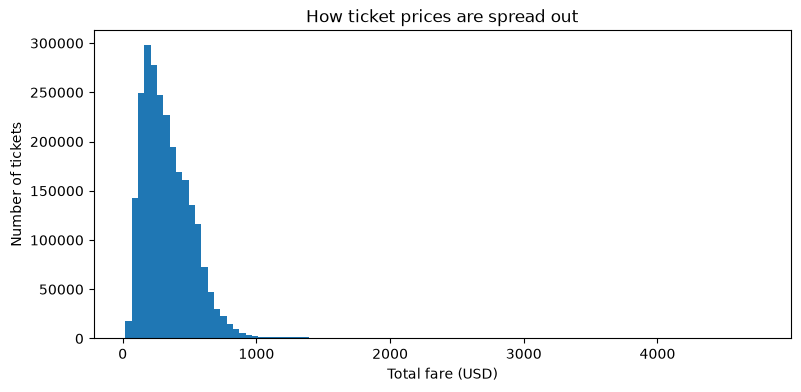

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))
plt.hist(df['totalFare'], bins=100)
plt.xlabel('Total fare (USD)')
plt.ylabel('Number of tickets')
plt.title('How ticket prices are spread out')
plt.show()

## Chart 2 · Does booking early save money?

We calculate **days_left** = flight date minus the date the price was checked, then take the average price for each value of days_left.

In [ ]:
days_left = (pd.to_datetime(df['flightDate']) - pd.to_datetime(df['searchDate'])).dt.days
avg_by_days = df['totalFare'].groupby(days_left).mean()

plt.figure(figsize=(9, 4))
plt.plot(avg_by_days.index, avg_by_days.values, marker='o')
plt.xlabel('Days left before the flight')
plt.ylabel('Average total fare (USD)')
plt.title('Average price vs days before departure')
plt.show()

## Chart 3 · Non-stop vs connecting flights

In [ ]:
avg_by_stop = df.groupby('isNonStop')['totalFare'].mean()
avg_by_stop.index = ['Non-stop' if v else 'Connecting' for v in avg_by_stop.index]

plt.figure(figsize=(5, 4))
plt.bar(avg_by_stop.index, avg_by_stop.values)
plt.ylabel('Average total fare (USD)')
plt.title('Non-stop vs connecting')
plt.show()
avg_by_stop